ГЕНЕРАЦІЯ ІМЕН ЗА ДОПОМОГОЮ
РЕКУРЕНТНИХ НЕЙРОННИХ МЕРЕЖ (RNN)

Мета роботи: Навчитися використовувати рекурентні нейронні мережі для
генерації тексту, зокрема для створення нових імен та лозунгів. Розібратися
з основами RNN, процесом навчання на текстових даних, а також з тим, як
налаштувати та оптимізувати модель для досягнення якісних результатів у
генерації тексту. Для роботи буде використовуватися датасет імен який
знаходиться на сторінці курсу.

Рекурентні нейронні мережі особливі тим, що вони можуть
враховувати послідовність входів, тобто аналізувати попередні символи,
щоб передбачати наступний. Це досягається за рахунок передачі
прихованого стану (hidden state) на кожному кроці, який виступає
своєрідною «пам’яттю» мережі.

Перший етап - завантаження та підготовка даних, їх аналіз

Імпортуємо необхідні бібліотеки

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np
from random import sample


Завантажуємо датасет імен

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving names.txt to names.txt


In [ ]:
file_path = "names.txt"
with open(file_path, "r", encoding="utf-8") as f:
 names = f.read().splitlines()

In [ ]:
# Додаємо EOS до кожного імені щоб позначити закінчення рядка
eos_token = "*"
names = [' ' + name + eos_token for name in names]

# Унікальні символи та їх кодування
unique_chars = sorted(set("".join(names)))
char_to_id = {char: idx + 1 for idx, char in enumerate(unique_chars)} #
# Починаємо з 1
id_to_char = {idx: char for char, idx in char_to_id.items()}
vocab_size = len(char_to_id)


Результат

In [ ]:
# Аналіз довжин імен
name_lengths = [len(name) for name in names]
# Виведення базової інформації
print(f"Кількість імен: {len(names)}")
print(f"Унікальних символів: {vocab_size}")
print(f"Перші 5 імен: {names[:5]}")
print(f"Унікальні символи: {unique_chars}")

Кількість імен: 9408
Унікальних символів: 52
Перші 5 імен: ['  Ababko**', '  Abaev**', '  Abagyan**', '  Abaidulin**', '  Abaidullin**']
Унікальні символи: [' ', "'", '*', ',', '-', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'w', 'y', 'z']


In [ ]:
# Перевіряємо словники
print(f"Унікальні символи: {unique_chars}")
print(f"char_to_id: {char_to_id}")
print(f"id_to_char: {id_to_char}")
print(f"vocab_size: {vocab_size}")

Унікальні символи: [' ', "'", '*', ',', '-', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'w', 'y', 'z']
char_to_id: {' ': 1, "'": 2, '*': 3, ',': 4, '-': 5, 'A': 6, 'B': 7, 'C': 8, 'D': 9, 'E': 10, 'F': 11, 'G': 12, 'H': 13, 'I': 14, 'J': 15, 'K': 16, 'L': 17, 'M': 18, 'N': 19, 'O': 20, 'P': 21, 'R': 22, 'S': 23, 'T': 24, 'U': 25, 'V': 26, 'Y': 27, 'Z': 28, 'a': 29, 'b': 30, 'c': 31, 'd': 32, 'e': 33, 'f': 34, 'g': 35, 'h': 36, 'i': 37, 'j': 38, 'k': 39, 'l': 40, 'm': 41, 'n': 42, 'o': 43, 'p': 44, 'r': 45, 's': 46, 't': 47, 'u': 48, 'v': 49, 'w': 50, 'y': 51, 'z': 52}
id_to_char: {1: ' ', 2: "'", 3: '*', 4: ',', 5: '-', 6: 'A', 7: 'B', 8: 'C', 9: 'D', 10: 'E', 11: 'F', 12: 'G', 13: 'H', 14: 'I', 15: 'J', 16: 'K', 17: 'L', 18: 'M', 19: 'N', 20: 'O', 21: 'P', 22: 'R', 23: 'S', 24: 'T', 25: 'U', 26: 'V', 27: 'Y', 2

In [ ]:
# Перевіряємо словники
print(f"Розмір словника: {vocab_size}")
print(f"Індекси словника: {list(char_to_id.values())}")
# Виведення базової інформації
print(f"Кількість імен: {len(names)}")
print(f"Унікальних символів: {vocab_size}")
print(f"Перші 5 імен: {names[:5]}")

Розмір словника: 52
Індекси словника: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52]
Кількість імен: 9408
Унікальних символів: 52
Перші 5 імен: ['  Ababko**', '  Abaev**', '  Abagyan**', '  Abaidulin**', '  Abaidullin**']


Створюємо функцію для конвертації імен у матрицю токенів

In [ ]:
# Створення матриці токенів
def to_matrix(data,
              token_dict,
              max_len=None,
              dtype="int32",
              batch_first=True):
  max_len = max_len or max(map(len, data))
  data_ix = np.zeros((len(data), max_len), dtype=dtype) + token_dict[" "]
  for i, name in enumerate(data):
    line_ix = [token_dict[c] for c in name]
    data_ix[i, :len(line_ix)] = line_ix
  if not batch_first:
    data_ix = np.transpose(data_ix)
  return data_ix


In [ ]:

matrix = to_matrix(names, char_to_id)


Додаємо графіки для аналізу розподілів довжин

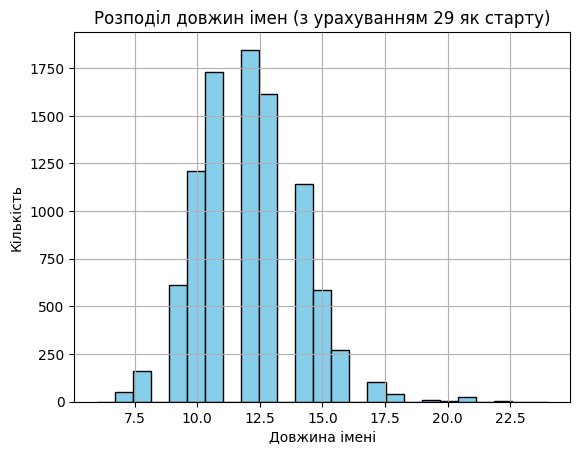

In [ ]:
# Візуалізація розподілу довжин імен
plt.hist(name_lengths, bins=25, color="skyblue", edgecolor="black")
plt.title("Розподіл довжин імен (з урахуванням 29 як старту)")
plt.xlabel("Довжина імені")
plt.ylabel("Кількість")
plt.grid(True)
plt.show()

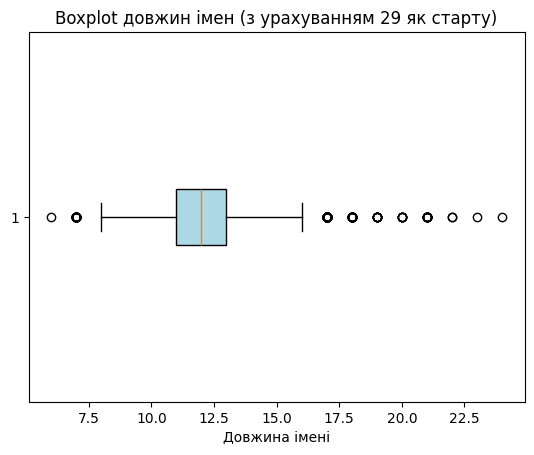

In [ ]:
# Boxplot довжин імен
plt.boxplot(name_lengths, vert=False, patch_artist=True,
boxprops=dict(facecolor="lightblue"))
plt.title("Boxplot довжин імен (з урахуванням 29 як старту)")
plt.xlabel("Довжина імені")
plt.show()

Виводимо декілька рядків матриці

In [ ]:

print("Приклад матриці токенів (з урахуванням 29 на початку):")
print(matrix[:5])

Приклад матриці токенів (з урахуванням 29 на початку):
[[ 1  1  6 30 29 30 39 43  3  3  1  1  1  1  1  1  1  1  1  1  1  1  1  1]
 [ 1  1  6 30 29 33 49  3  3  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]
 [ 1  1  6 30 29 35 51 29 42  3  3  1  1  1  1  1  1  1  1  1  1  1  1  1]
 [ 1  1  6 30 29 37 32 48 40 37 42  3  3  1  1  1  1  1  1  1  1  1  1  1]
 [ 1  1  6 30 29 37 32 48 40 40 37 42  3  3  1  1  1  1  1  1  1  1  1  1]]


Тепер розробимо клас CharRNNCell для побудови рекурентної
нейронної мережі. Цей клас реалізує базову рекурентну нейронну мережу
для роботи із символами.

In [ ]:
# Клас для рекурентної нейронної мережі
class CharRNNCell(nn.Module):
    def __init__(self, num_tokens, embedding_size=16, rnn_num_units=64):
        super().__init__()
        self.num_units = rnn_num_units

        # Шар для векторного подання символів
        self.embedding = nn.Embedding(num_tokens, embedding_size)

        # Шар для оновлення прихованого стану
        self.rnn_update = nn.Linear(
            embedding_size + rnn_num_units,
            rnn_num_units
        )

        # Шар для обчислення ймовірностей наступного символу
        self.rnn_to_logits = nn.Linear(rnn_num_units, num_tokens)

    def forward(self, x, h_prev):
        # Перетворення токенів у ембеддинги
        x_emb = self.embedding(x)
        # print(f"x_emb shape: {x_emb.shape}")  # Debug

        # Конкатенація поточного входу і попереднього прихованого стану
        # print(f"h_prev shape: {h_prev.shape}")  # Debug
        x_and_h = torch.cat([x_emb, h_prev], dim=1)
        # print(f"x_and_h shape: {x_and_h.shape}")  # Debug

        # Оновлення прихованого стану
        # print(f"Expected rnn_update input size: {self.rnn_update.in_features}")  # Debug
        h_next = self.rnn_update(x_and_h)
        h_next = torch.tanh(h_next)

        # Обчислення логітів (ймовірностей)
        logits = self.rnn_to_logits(h_next)

        # Повертаємо новий прихований стан і лог-ймовірності
        return h_next, F.log_softmax(logits, dim=-1)

    def initial_state(self, batch_size):
        # Ініціалізація прихованого стану
        return Variable(torch.zeros(batch_size, self.num_units))

Далі  реалізовуємо функцію для роботи з мережею(обчислення ймовірностей для послідовності, генерація нових символів)

In [ ]:
# Функція для проходження послідовності через RNN
def rnn_loop(rnn, batch_index):
    """Computes log P(next_character) for all time-steps in names_ix"""

    batch_size, max_length = batch_index.size()
    hid_state = rnn.initial_state(batch_size)
    logprobs = []

    for x_t in batch_index.transpose(0, 1):
        hid_state, logp_next = rnn(x_t, hid_state)
        logprobs.append(logp_next)

    return torch.stack(logprobs, dim=1)


def generate_sample(rnn, seed_phrase=" ", max_length=10, temperature=1.0):

    if not seed_phrase:
        seed_phrase = " "

    x_sequence = [
        char_to_id.get(token, char_to_id[" "])
        for token in seed_phrase
    ]

    if len(x_sequence) == 0:
        raise ValueError("Seed phrase is empty or contains invalid characters.")

    x_sequence = torch.tensor([x_sequence], dtype=torch.int64)
    hid_state = rnn.initial_state(batch_size=1)

    # Фіксація розміру прихованого стану
    if hid_state.size(1) != rnn.num_units:
        hid_state = torch.zeros(1, rnn.num_units)

    # Проганяємо seed-фразу (окрім останнього символу)
    for t in range(len(seed_phrase) - 1):
        hid_state, _ = rnn(x_sequence[:, t], hid_state)

        if hid_state.size(1) != rnn.num_units:
            hid_state = torch.zeros(1, rnn.num_units)

    # Генерація нових символів
    for _ in range(max_length - len(seed_phrase)):
        hid_state, logp_next = rnn(x_sequence[:, -1], hid_state)

        p_next = torch.softmax(logp_next / temperature, dim=-1).data.numpy()[0]
        next_ix = np.random.choice(len(p_next), p=p_next)

        x_sequence = torch.cat(
            [x_sequence, torch.tensor([[next_ix]])],
            dim=1
        )

        # Зупиняємо генерацію на EOS
        if id_to_char.get(next_ix) == eos_token:
            break

        # Зупиняємо генерацію, якщо символ — пробіл
        if id_to_char.get(next_ix) == " ":
            break

    return "".join(
        [
            id_to_char.get(ix, " ")
            for ix in x_sequence.data.numpy()[0]
            if (ix and id_to_char[ix] != eos_token)
        ]
    )

Створюємо об'єкт класу

In [ ]:
# Ініціалізація моделі
num_tokens = vocab_size + 1  # Кількість унікальних символів у словнику
embedding_size = 128
rnn_num_units = 128

char_rnn = CharRNNCell(
    num_tokens=num_tokens,
    embedding_size=embedding_size,
    rnn_num_units=rnn_num_units
)

opt = torch.optim.Adam(char_rnn.parameters())  # Оптимізатор
history_manual = []  # Для збереження втрат

MAX_LENGTH = max(name_lengths)  # Максимальна довжина імен

Навчаємо мережу

In [ ]:
import time
# Симуляція процесу навчання
for i in range(10000):
    start_time_m = time.time()
    # Підготовка батча
    batch_names = sample(names, 32)
    batch_ix = to_matrix(batch_names, char_to_id, max_len=MAX_LENGTH)
    batch_ix = torch.tensor(batch_ix, dtype=torch.int64)

    # Прогон через RNN
    logp_seq = rnn_loop(char_rnn, batch_ix)

    # Обчислення втрат
    predictions_logp = logp_seq[:, :-1]          # Лог-імовірності (без останнього символу)
    actual_next_tokens = batch_ix[:, 1:]         # Наступні символи

    loss = -torch.mean(
        torch.gather(
            predictions_logp,
            dim=2,
            index=actual_next_tokens[:, :, None]
        )
    )

    # Зворотний прохід і оновлення ваг
    loss.backward()
    opt.step()
    opt.zero_grad()

    # Вивід кожні 100 ітерацій
    if i % 100 == 0:
        print(f"Iteration {i}, Loss: {loss.item():.4f}")
        history_manual.append(loss.item())
total_time_m =  time.time() -start_time_m

print(f"\nTime: {total_time_m:.4f}")


Iteration 0, Loss: 3.8952
Iteration 100, Loss: 0.8631
Iteration 200, Loss: 0.8485
Iteration 300, Loss: 0.7639
Iteration 400, Loss: 0.8522
Iteration 500, Loss: 0.7811
Iteration 600, Loss: 0.7761
Iteration 700, Loss: 0.8082
Iteration 800, Loss: 0.7480
Iteration 900, Loss: 0.6597
Iteration 1000, Loss: 0.7182
Iteration 1100, Loss: 0.7144
Iteration 1200, Loss: 0.7072
Iteration 1300, Loss: 0.6829
Iteration 1400, Loss: 0.6807
Iteration 1500, Loss: 0.7268
Iteration 1600, Loss: 0.6853
Iteration 1700, Loss: 0.7021
Iteration 1800, Loss: 0.7071
Iteration 1900, Loss: 0.7099
Iteration 2000, Loss: 0.6804
Iteration 2100, Loss: 0.6794
Iteration 2200, Loss: 0.7245
Iteration 2300, Loss: 0.7005
Iteration 2400, Loss: 0.7681
Iteration 2500, Loss: 0.7235
Iteration 2600, Loss: 0.6445
Iteration 2700, Loss: 0.6212
Iteration 2800, Loss: 0.6369
Iteration 2900, Loss: 0.6103
Iteration 3000, Loss: 0.6657
Iteration 3100, Loss: 0.7118
Iteration 3200, Loss: 0.6680
Iteration 3300, Loss: 0.6669
Iteration 3400, Loss: 0.67

Будуємо графік втрат для перевірки на збіжність та генеруємо приклади за різними значеннми температури

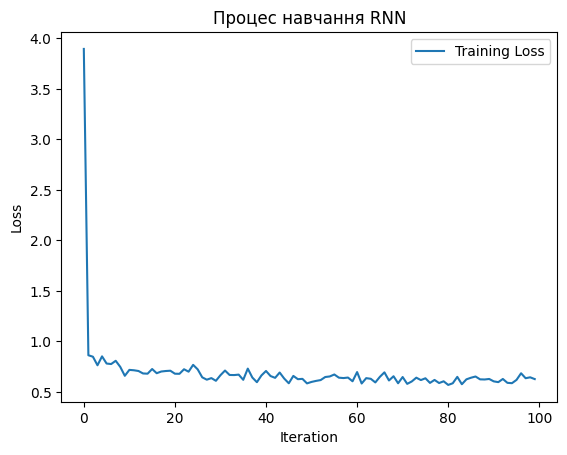


Generated Names:

Температура 0.01:
Abazov
Abazov
Abazov
Abazov
Abazov
Abazov
Abazov
Abazov

Температура 0.2:
Abrameloff
Abazov
Abarov
Abrameloff
Abazov
Ablintsev
Abrameloff
Abramenko

Температура 0.5:
Ablintsev
Abramets
Abrameloff
Abramenko
Abalov
Ablintsev
Abazov
Abramenko

Температура 1.0:
Abgov
Abaruev
Abullin
Abeldin
Abdarbasky
Abazaev
Abaev
Abgul

Температура 2.0:
Abrabieff
Abilg
Abauchyk
Abazchum
AbovkEi
AbVDinhmat
Abrosov
AbeiJaly

Температура 5.0:
AbleFvCCBV
Abat-eAneK
AbnAZheeTs
AbtI
AbFPsGAsiv
AbsUCrdenj
AbCMnRTyGh
AbmfbahHwe


In [ ]:
# Побудова графіка втрат
plt.plot([i for i in range(100)], history_manual, label="Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.title("Процес навчання RNN")
plt.show()

# Перевірка збіжності
assert np.mean(history_manual[:10]) > np.mean(history_manual[-10:]), "RNN didn't converge."

# Генерація прикладів
print("\nGenerated Names:")

for temp in [0.01, 0.2, 0.5, 1.0, 2.0, 5.0]:
  print(f"\nТемпература {temp}:")
  for _ in range(8):
        print(
            generate_sample(
                char_rnn,
                seed_phrase="Ab",
                temperature=temp
            )
        )

При генерації нових імен(прізьвищ) модель демонструє різну поведінку залежно від значення параметра температури. При дуже низькій температурі, наприклад 0.01, вона майже завжди відтворює одне і те саме ім’я, демонструючи високу передбачуваність. Зі збільшенням температури імена починають варіюватися, з’являються нові комбінації букв і різні закінчення, але вони все ще зберігають певні впізнавані шаблони. При температурі 1.0 модель генерує більш різноманітні та менш передбачувані імена, а при ще більших значеннях  імена стають дуже нестандартними, іноді без смислової структури. Таким чином, температура контролює баланс між передбачуваністю та креативністю генерації: низькі значення дають стабільні шаблони, високі — хаотичну різноманітність.


Далі реалізуємо рекурентну мережу через бібліотеку PyTorch

Реалізуємо клас рекурентної мережі

In [ ]:

class CharRNN(nn.Module):

    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.hidden_dim = hidden_dim

    def forward(self, x, hidden):
        x = self.embedding(x)
        out, hidden = self.rnn(x, hidden)
        logits = self.fc(out)
        return logits, hidden

    def init_hidden(self, batch_size):
        return torch.zeros(1, batch_size, self.hidden_dim)

Додамо функцію для генерації прикладів

In [ ]:
# Функція для генерації
def generate_sample(model, seed_phrase=" ", max_len=20, temperature=1.0):

    model.eval()

    x_sequence = [
        char_to_id.get(token, char_to_id[" "])
        for token in seed_phrase
    ]

    x_sequence = torch.tensor([x_sequence], dtype=torch.int64)
    hidden = model.init_hidden(batch_size=1)

    for _ in range(max_len - len(seed_phrase)):

        logits, hidden = model(x_sequence[:, -1:], hidden)

        probs = torch.softmax(
            logits / temperature,
            dim=-1
        ).data.numpy()[0, -1]

        next_ix = np.random.choice(len(probs), p=probs)

        x_sequence = torch.cat(
            [x_sequence, torch.tensor([[next_ix]])],
            dim=1
        )

        # Зупиняємо генерацію на EOS
        if id_to_char.get(next_ix) == eos_token:
            break

        # Зупиняємо генерацію, якщо символ — пробіл
        if id_to_char.get(next_ix) == " ":
            break

    return "".join(
        [
            id_to_char[ix]
            for ix in x_sequence.data.numpy()[0]
            if id_to_char[ix] != eos_token
        ]
    )

Реалізуємо цикл навчання

In [ ]:
for epoch in range(n_epochs):
    start_time_a = time.time()

    batch_indices = sample(range(len(names)), batch_size)

    # Перетворюємо у Tensor
    batch_x = torch.tensor(names_matrix_auto[batch_indices, :-1], dtype=torch.long)
    batch_y = torch.tensor(names_matrix_auto[batch_indices, 1:], dtype=torch.long)

    hidden = model_auto.init_hidden(batch_size)

    logits, _ = model_auto(batch_x, hidden)

    loss = criterion(
        logits.view(-1, vocab_size + 1),
        batch_y.view(-1)
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")
        history_auto.append(loss.item())

total_time_a = time.time() - start_time_a
print(f"\nTime: {total_time_a:.4f}")

Epoch 0, Loss: 0.7024
Epoch 100, Loss: 0.8230
Epoch 200, Loss: 0.7761
Epoch 300, Loss: 0.7930
Epoch 400, Loss: 0.7844
Epoch 500, Loss: 0.7994
Epoch 600, Loss: 0.7786
Epoch 700, Loss: 0.8100
Epoch 800, Loss: 0.7457
Epoch 900, Loss: 0.7401
Epoch 1000, Loss: 0.7618
Epoch 1100, Loss: 0.7615
Epoch 1200, Loss: 0.7354
Epoch 1300, Loss: 0.7856
Epoch 1400, Loss: 0.7636
Epoch 1500, Loss: 0.7621
Epoch 1600, Loss: 0.7025
Epoch 1700, Loss: 0.7322
Epoch 1800, Loss: 0.6889
Epoch 1900, Loss: 0.7542
Epoch 2000, Loss: 0.7400
Epoch 2100, Loss: 0.7449
Epoch 2200, Loss: 0.7238
Epoch 2300, Loss: 0.7929
Epoch 2400, Loss: 0.6690
Epoch 2500, Loss: 0.7302
Epoch 2600, Loss: 0.7231
Epoch 2700, Loss: 0.7731
Epoch 2800, Loss: 0.8462
Epoch 2900, Loss: 0.7224
Epoch 3000, Loss: 0.7789
Epoch 3100, Loss: 0.7494
Epoch 3200, Loss: 0.7908
Epoch 3300, Loss: 0.7554
Epoch 3400, Loss: 0.7810
Epoch 3500, Loss: 0.7870
Epoch 3600, Loss: 0.6894
Epoch 3700, Loss: 0.7216
Epoch 3800, Loss: 0.7278
Epoch 3900, Loss: 0.6774
Epoch 4000, 

Візуалізуємо результати

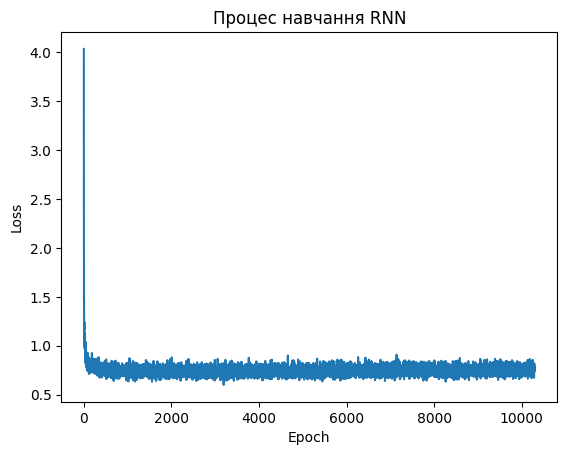


Generated Names:

Температура 0.01:
Aronov
Aronov
Aronov
Aronov
Aronov
Aronov
Aronov
Aronov

Температура 0.2:
Arov
Aronov
Aroshevich
Aronov
Aronov
Aronov
Aronov
Aronov

Температура 0.5:
Aronsky
Aronovsky
Arov
Aronov
Aros
Aron
Aronovich
Aroshevkin

Температура 1.0:
Arov
Aromanetsky
Aronontyan
Aronok
Arosilin
Aragolin
Aryanko
Arochkov

Температура 2.0:
Aryrkyoezooareveevic
AraiFRyhobobojnavyi
Arovskinoowakhiazsky
Aruh
Arisarespruevbebfihi
Aroev
Arakhkotsky
Aritce


In [ ]:
# Графік втрат
plt.plot(history_auto)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Процес навчання RNN")
plt.show()

# Генерація прикладів
print("\nGenerated Names:")

for temp in [0.01, 0.2, 0.5, 1.0, 2.0]:
    print(f"\nТемпература {temp}:")

    for _ in range(8):
        print(
            generate_sample(
                model_auto,
                seed_phrase="Ar",
                temperature=temp
            )
        )

При використанні рекурентної мережі, створеної через бібліотеку, генерація імен демонструє більш стабільні та впізнавані патерни порівняно з ручною реалізацією. При низькій температурі 0.01 модель майже завжди генерує одне й те саме ім’я, що свідчить про високу передбачуваність. Зі збільшенням температури  з’являється більше варіацій імен, але вони залишаються близькими до реалістичних шаблонів. При температурі 1.0 і вище генерація стає більш різноманітною, проте імена все ще мають певну структурну схожість, на відміну від ручної реалізації, де при високих температурах з’являлися хаотичні та беззмістовні комбінації. Тобто, бібліотечна реалізації має кращу генерацію імен(прізьвищ) і зберігає певний баланс між передбачуваністю та різноманітністю. Окрім того, швидкість навчання є вищою, а складність реалізації нижчою


Складемо таблицю для порівняння двох підходів:
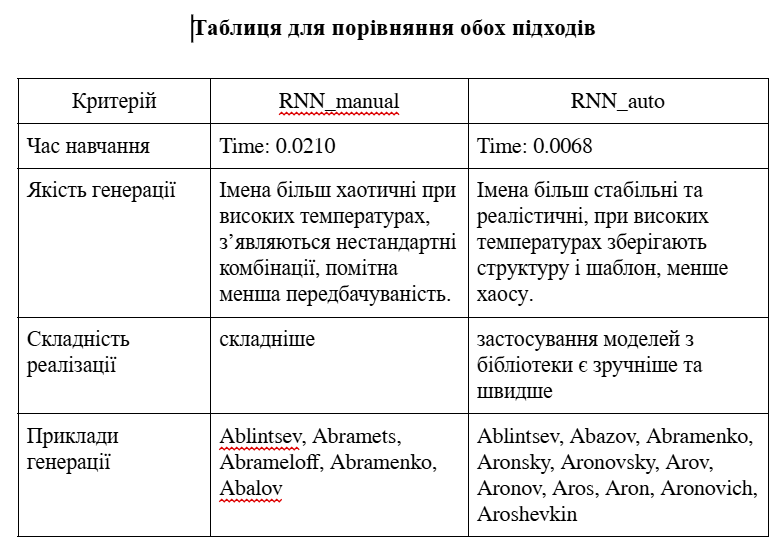

Температура безпосередньо впливає на різноманітність і передбачуваність згенерованих прикладів. При низьких значеннях мережа  майже завжди повторює одні й ті самі шаблони імен, тому генерація стабільна, але мало варіативна. При середніх значеннях імена стають різноманітними, але все ще реалістичними та впізнаваними. Високі значення температури (2.0 і більше) роблять генерацію хаотичною: з’являються нестандартні, іноді беззмістовні комбінації букв.


Вбудована RNN із бібліотеки дає переваги над ручною реалізацією: вона забезпечує більш стабільну генерацію, спрощує код і пришвидшує навчання, а також надає доступ до оптимізованих методів і зручних функцій.




Якщо збільшити розмір прихованого шару, модель зможе зберігати більше інформації про попередні символи, що підвищує якість генерації і дозволяє відтворювати складніші шаблони, але збільшує час навчання і потребу в даних. Зменшення даного праметру робить модель менш потужною, генерація стає простішою і менш різноманітною.

Кількість епох навчання також впливає: більше епох дозволяє моделі краще адаптуватися до шаблонів імен, зменшуючи втрати і покращуючи передбачуваність, тоді як недостатня кількість епох призведе до поганої генерації та низької якості імен.

 Як зміняться результати, якщо видалити EOS (*) і зупиняти генерацію за
іншими умовами?


Визначимо вплив видалення даного спеціального символу для обох мереж

Для моделі, створеної вручну

In [ ]:


def generate_sample_space(rnn, seed_phrase=" ", max_length=10, temperature=1.0):

    if not seed_phrase:
        seed_phrase = " "

    x_sequence = [
        char_to_id.get(token, char_to_id[" "])
        for token in seed_phrase
    ]

    if len(x_sequence) == 0:
        raise ValueError("Seed phrase is empty or contains invalid characters.")

    x_sequence = torch.tensor([x_sequence], dtype=torch.int64)
    hid_state = rnn.initial_state(batch_size=1)

    # Фіксація розміру прихованого стану
    if hid_state.size(1) != rnn.num_units:
        hid_state = torch.zeros(1, rnn.num_units)

    # Проганяємо seed-фразу (окрім останнього символу)
    for t in range(len(seed_phrase) - 1):
        hid_state, _ = rnn(x_sequence[:, t], hid_state)

        if hid_state.size(1) != rnn.num_units:
            hid_state = torch.zeros(1, rnn.num_units)

    # Генерація нових символів
    for _ in range(max_length - len(seed_phrase)):
        hid_state, logp_next = rnn(x_sequence[:, -1], hid_state)

        p_next = torch.softmax(logp_next / temperature, dim=-1).data.numpy()[0]
        next_ix = np.random.choice(len(p_next), p=p_next)

        x_sequence = torch.cat(
            [x_sequence, torch.tensor([[next_ix]])],
            dim=1
        )

        # Зупиняємо генерацію, якщо символ — пробіл
        if id_to_char.get(next_ix) == " ":
            break

    return "".join(
        [
            id_to_char.get(ix, " ")
            for ix in x_sequence.data.numpy()[0]
            if (ix and id_to_char[ix] != eos_token)
        ]
    )

In [ ]:
for temp in [0.01, 0.2, 0.5, 1.0, 2.0, 5.0]:
  print(f"\nТемпература {temp}:")
  for _ in range(8):
        print(
            generate_sample_space(
                char_rnn,
                seed_phrase="Ab",
                temperature=temp
            )
        )


Температура 0.01:
Abazov 
Abazov 
Abazov 
Abazov 
Abazov 
Abazov 
Abazov 
Abazov 

Температура 0.2:
Abaev 
Abramelov
Ablov 
Abramelov
Abaev 
Abazeeff
Abalov 
Abrameloff

Температура 0.5:
Ablinson
Ablinov 
Abaev 
Ablintsev
Abin 
Abloff 
Ablinoff
Abramelov

Температура 1.0:
Abgedov 
Abatiurin
Abov 
Abeev 
Abrejnberg
Ablagidjan
Abrov 
Abakin 

Температура 2.0:
Abraniefv
Abruli 
Abrlazov
Abewdin 
Abrasyhish
Abakomaih
Abvsugimo
Abze 

Температура 5.0:
AbrcDekeDD
AbGidLsrsn
AbJHTckYth
AbANsUAv
AbwOriCha
AbUyzfv,rh
Abueh'zyIO
AblGayjPPn


Для моделі, створеної через RNN модуль

In [ ]:
# Функція для генерації
def generate_sample_space(model, seed_phrase=" ", max_len=20, temperature=1.0):

    model.eval()

    x_sequence = [
        char_to_id.get(token, char_to_id[" "])
        for token in seed_phrase
    ]

    x_sequence = torch.tensor([x_sequence], dtype=torch.int64)
    hidden = model.init_hidden(batch_size=1)

    for _ in range(max_len - len(seed_phrase)):

        logits, hidden = model(x_sequence[:, -1:], hidden)

        probs = torch.softmax(
            logits / temperature,
            dim=-1
        ).data.numpy()[0, -1]

        next_ix = np.random.choice(len(probs), p=probs)

        x_sequence = torch.cat(
            [x_sequence, torch.tensor([[next_ix]])],
            dim=1
        )

        # Зупиняємо генерацію, якщо символ — пробіл
        if id_to_char.get(next_ix) == " ":
            break

    return "".join(
        [
            id_to_char[ix]
            for ix in x_sequence.data.numpy()[0]
            if id_to_char[ix] != eos_token
        ]
    )

In [ ]:
# Генерація прикладів
print("\nGenerated Names:")

for temp in [0.01, 0.2, 0.5, 1.0, 2.0]:
    print(f"\nТемпература {temp}:")

    for _ in range(8):
        print(
            generate_sample_space(
                model_auto,
                seed_phrase="Ar",
                temperature=temp
            )
        )


Generated Names:

Температура 0.01:
Aronov 
Aronov 
Aronov 
Aronov 
Aronov 
Aronov 
Aronov 
Aronov 

Температура 0.2:
Aronov 
Aroshevich 
Aronov 
Aronov 
Arov 
Aronov 
Arov 
Aronov 

Температура 0.5:
Aronsky 
Arogursky 
Arolev 
Aronov 
Arovich 
Aronov 
Arohmevichenko 
Aroshkov 

Температура 1.0:
Arohbagaev 
Aros 
Arosen 
Aroulov 
Arer 
Aroshevichin 
Aridyak 
Arnitse 

Температура 2.0:
Aravsennku 
Aruger 
Arueff 
AroshMaiamarohriveve
Aragoro 
Arolaev 
Aroomiro 
Arolsizhetenkolers


Отже, якщо видалити спеціальний символ кінця послідовності (EOS) і зупиняти генерацію імен тільки за пробілом, результати значно зміняться. По-перше, модель втратить чіткий сигнал про завершення послідовності, тому вона не знатиме, коли природно закінчувати генерацію. Замість цього зупинка відбуватиметься лише тоді, коли зустрінеться пробіл, що може призвести до неповних або обрізаних слів, особливо якщо ім’я складається з кількох частин без пробілів між ними. По-друге, без EOS зростає ймовірність, що модель буде генерувати зайві символи або повторювати частини тексту, намагаючись завершити слово. Як наслідок  - тексти стануть менш передбачуваними і менш структурованими.